# Seaborn Assignment


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_2024.csv")

df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df["quarter"] = df["order_date"].dt.quarter
df["profit_margin"] = df["profit"] / df["revenue"] * 100

print(df.shape)
print(df.info())
print(df.isna().sum().sum())
df.head()


(1000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         1000 non-null   object        
 1   order_date       1000 non-null   datetime64[ns]
 2   region           1000 non-null   object        
 3   category         1000 non-null   object        
 4   product          1000 non-null   object        
 5   quantity         1000 non-null   int64         
 6   unit_price       1000 non-null   float64       
 7   discount         1000 non-null   float64       
 8   revenue          1000 non-null   float64       
 9   profit           1000 non-null   float64       
 10  customer_age     1000 non-null   int64         
 11  customer_gender  1000 non-null   object        
 12  payment_method   1000 non-null   object        
 13  delivery_days    1000 non-null   int64         
 14  rating           1000 non-null

,order_id,order_date,region,category,product,quantity,unit_price,discount,revenue,profit,customer_age,customer_gender,payment_method,delivery_days,rating,month,quarter,profit_margin
0,ORD1001,2024-01-01,West,Clothing,Jeans,4,1730.0,0.00,6920.0,2636.14,45,Male,Debit Card,3,3.0,1,1,38.094509
1,ORD1002,2024-01-01,South,Sports,Dumbbell Set,1,2360.0,0.00,2360.0,690.43,39,Female,Credit Card,2,4.0,1,1,29.255508
2,ORD1003,2024-01-02,East,Clothing,T-Shirt,2,680.0,0.00,1360.0,456.07,31,Male,Credit Card,5,4.0,1,1,33.534559
3,ORD1004,2024-01-02,East,Clothing,Sneakers,3,2760.0,0.30,5796.0,887.30,24,Female,Credit Card,4,5.0,1,1,15.308834
4,ORD1005,2024-01-03,South,Clothing,Sneakers,2,2810.0,0.05,5339.0,1531.46,54,Female,UPI,2,3.0,1,1,28.684398


## Part A: Matplotlib (Q1 – Q10)


### Q1. Line Plot: Monthly Revenue


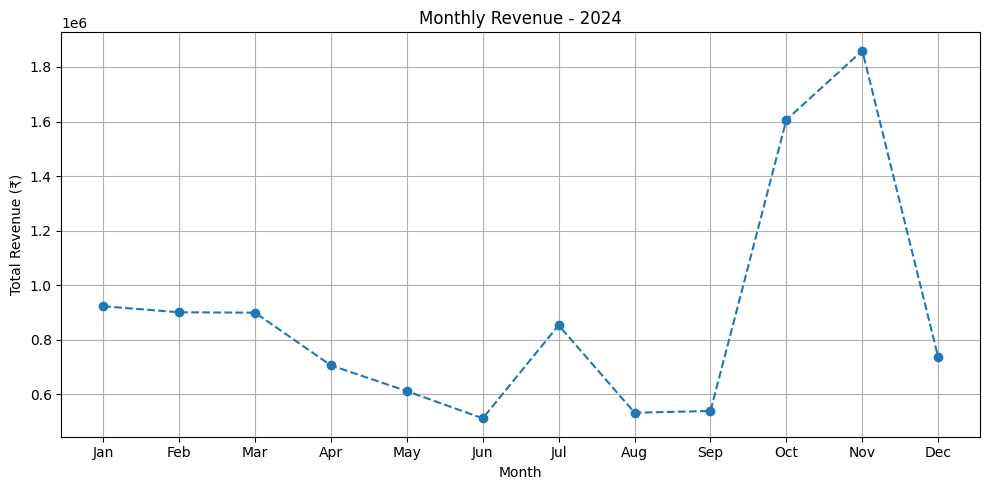

In [2]:
monthly_revenue = df.groupby("month")["revenue"].sum()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values,
         marker="o", linestyle="--")

plt.xticks(range(1, 13), month_names)
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.title("Monthly Revenue - 2024")
plt.grid(True)
plt.tight_layout()
plt.show()


### Q2. Bar Chart: Revenue by Category


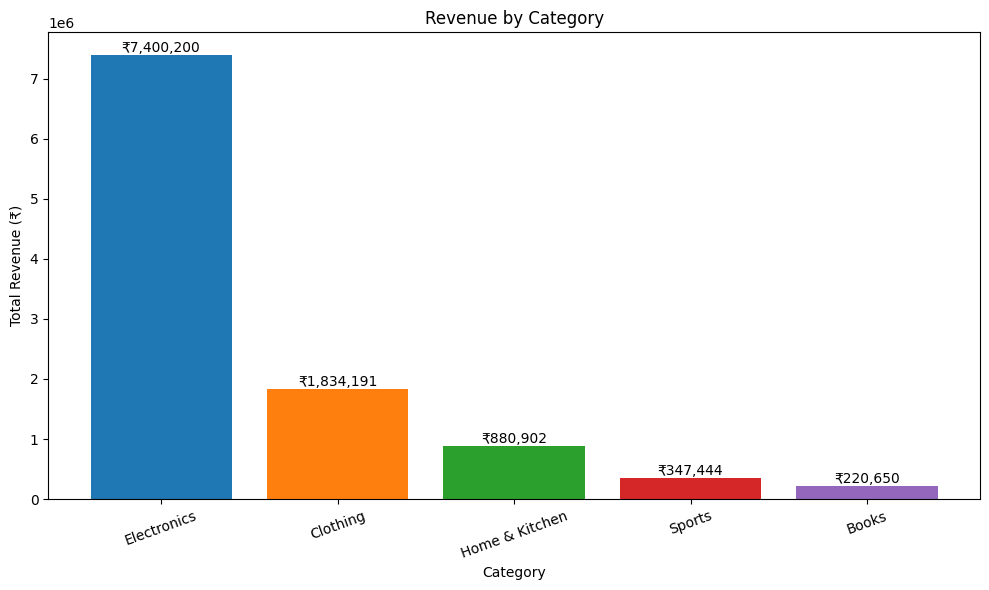

In [3]:
category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    category_revenue.index,
    category_revenue.values,
    color=plt.cm.tab10(np.arange(len(category_revenue)))
)

for bar, value in zip(bars, category_revenue.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Category")
plt.ylabel("Total Revenue (₹)")
plt.title("Revenue by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q3. Horizontal Bar Chart: Top 10 Products


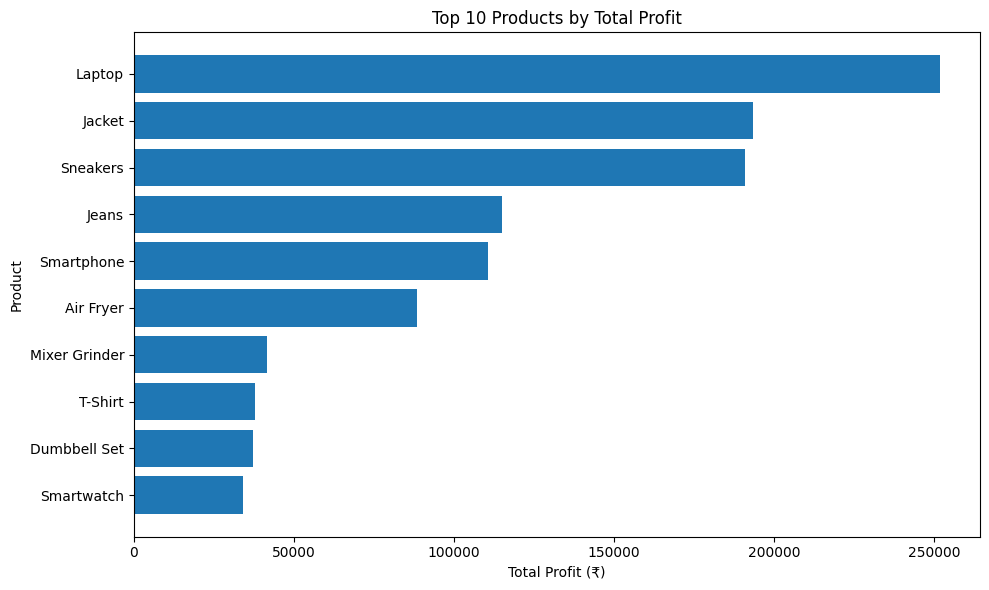

In [4]:
top_products = (
    df.groupby("product")["profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

# Reverse the order so the highest-profit product appears at the top.
top_products_plot = top_products.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_products_plot.index, top_products_plot.values)

plt.xlabel("Total Profit (₹)")
plt.ylabel("Product")
plt.title("Top 10 Products by Total Profit")
plt.tight_layout()
plt.show()


### Q4. Pie Chart: Payment Methods


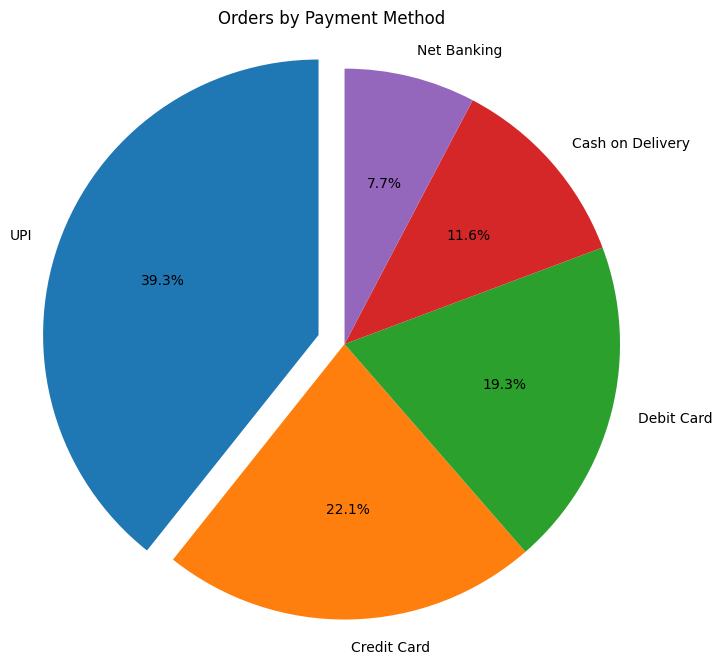

In [5]:
payment_counts = df["payment_method"].value_counts()
largest_method = payment_counts.idxmax()

explode = [
    0.1 if method == largest_method else 0
    for method in payment_counts.index
]

plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    explode=explode,
    startangle=90
)

plt.title("Orders by Payment Method")
plt.axis("equal")
plt.show()


### Q5. Histogram: Customer Age


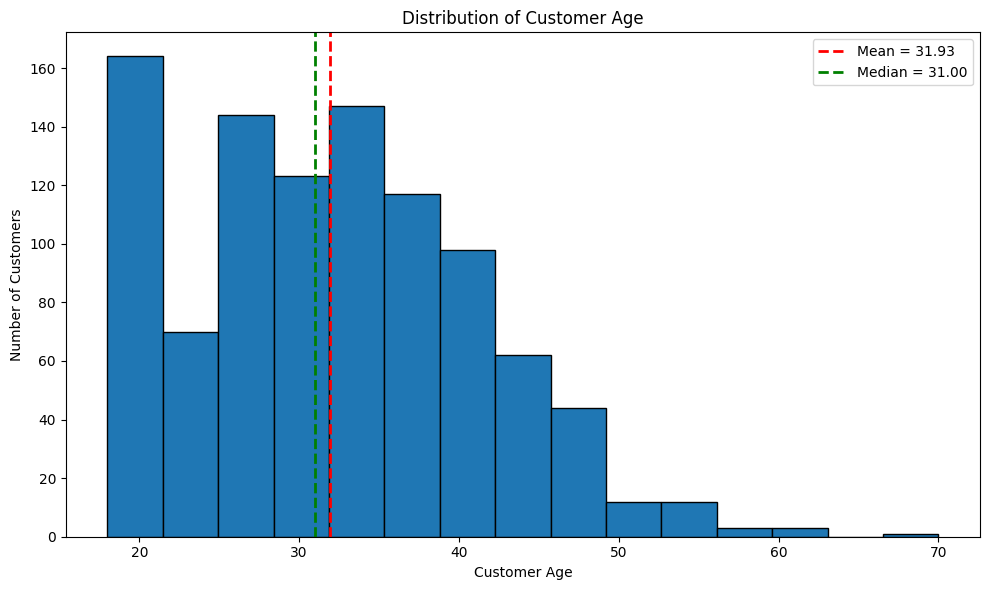

In [6]:
mean_age = df["customer_age"].mean()
median_age = df["customer_age"].median()

plt.figure(figsize=(10, 6))
plt.hist(df["customer_age"], bins=15, edgecolor="black")

plt.axvline(
    mean_age,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_age:.2f}"
)

plt.axvline(
    median_age,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_age:.2f}"
)

plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Age")
plt.legend()
plt.tight_layout()
plt.show()


### Q6. Scatter Plot: Revenue vs Profit


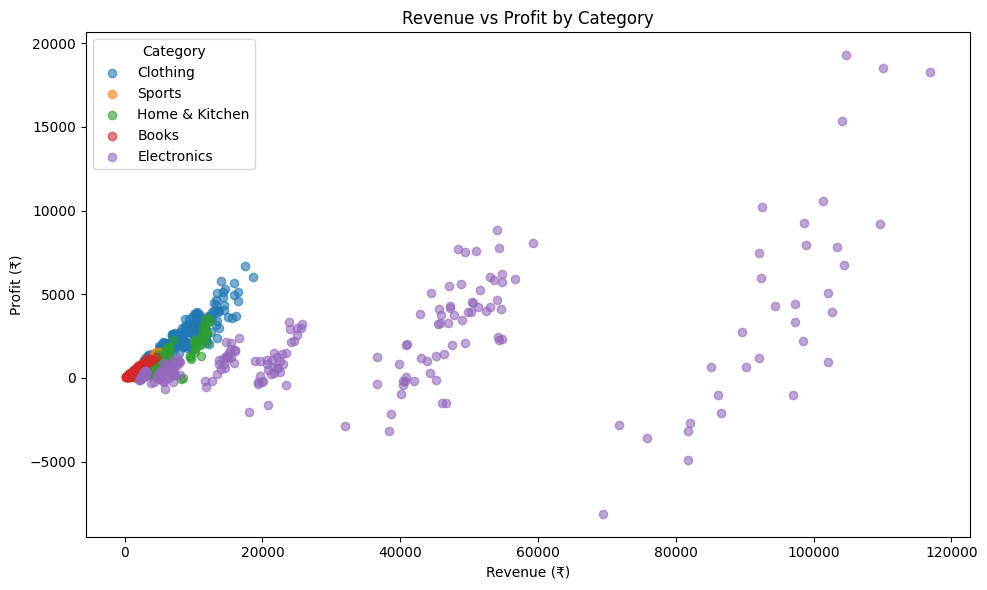

In [7]:
plt.figure(figsize=(10, 6))

for category in df["category"].unique():
    subset = df[df["category"] == category]
    plt.scatter(
        subset["revenue"],
        subset["profit"],
        alpha=0.6,
        label=category
    )

plt.xlabel("Revenue (₹)")
plt.ylabel("Profit (₹)")
plt.title("Revenue vs Profit by Category")
plt.legend(title="Category")
plt.tight_layout()
plt.show()


### Q7. Grouped Bar Chart: Quarterly Revenue by Region


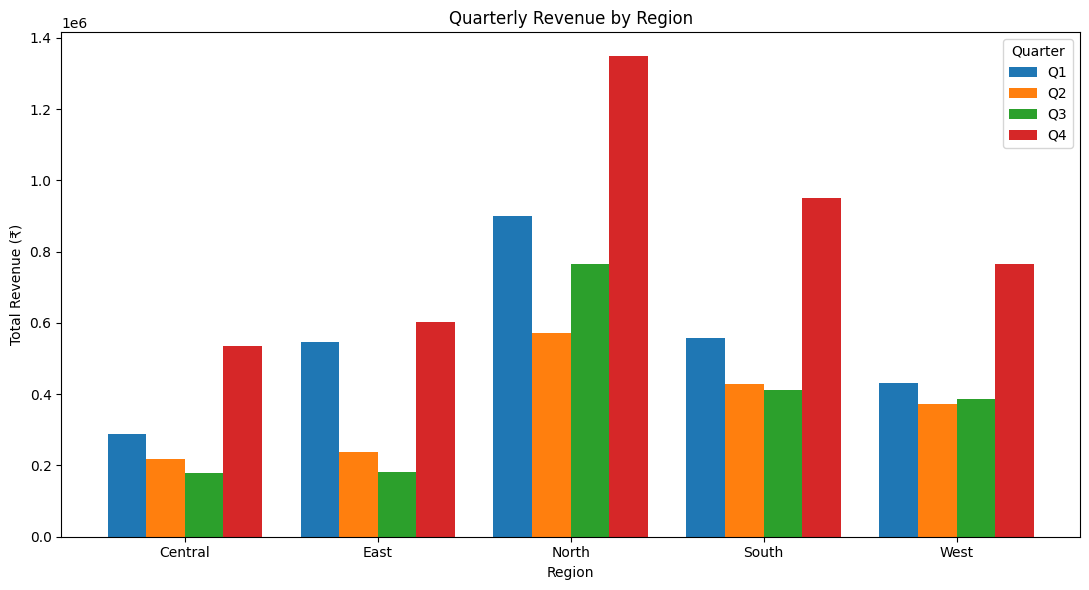

In [8]:
quarterly_revenue = df.pivot_table(
    index="region",
    columns="quarter",
    values="revenue",
    aggfunc="sum"
).reindex(columns=[1, 2, 3, 4])

regions = quarterly_revenue.index
x = np.arange(len(regions))
width = 0.2

plt.figure(figsize=(11, 6))

for i, quarter in enumerate([1, 2, 3, 4]):
    plt.bar(
        x + (i - 1.5) * width,
        quarterly_revenue[quarter],
        width,
        label=f"Q{quarter}"
    )

plt.xticks(x, regions)
plt.xlabel("Region")
plt.ylabel("Total Revenue (₹)")
plt.title("Quarterly Revenue by Region")
plt.legend(title="Quarter")
plt.tight_layout()
plt.show()


### Q8. Stacked Bar Chart: Monthly Orders by Category


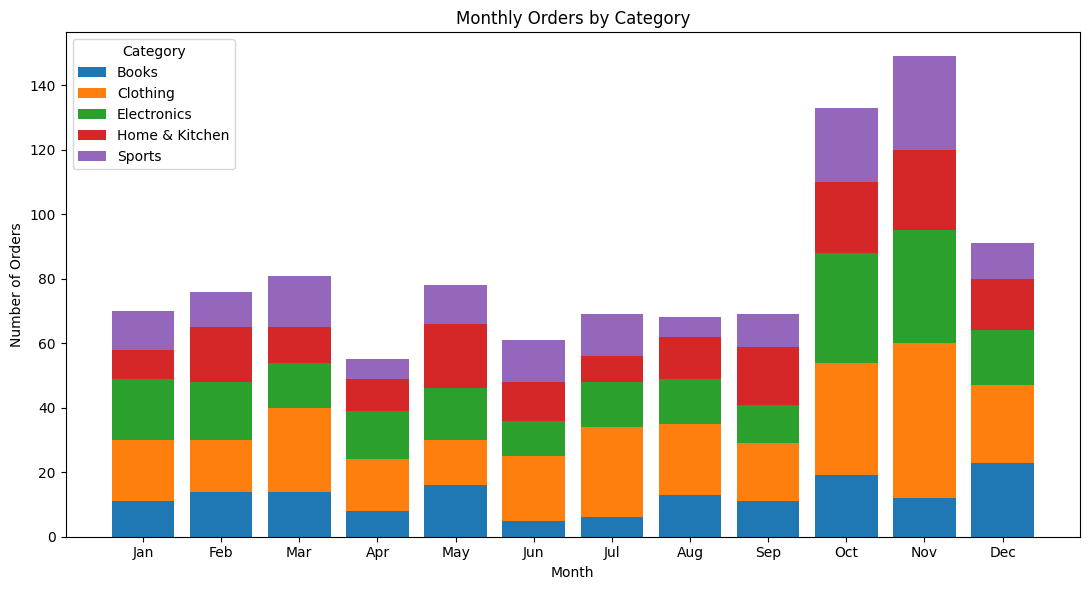

In [9]:
monthly_orders = pd.crosstab(df["month"], df["category"])
monthly_orders = monthly_orders.reindex(
    index=range(1, 13),
    columns=sorted(df["category"].unique()),
    fill_value=0
)

bottom = np.zeros(12)

plt.figure(figsize=(11, 6))

for category in monthly_orders.columns:
    values = monthly_orders[category].values
    plt.bar(
        range(1, 13),
        values,
        bottom=bottom,
        label=category
    )
    bottom += values

plt.xticks(range(1, 13), month_names)
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.title("Monthly Orders by Category")
plt.legend(title="Category")
plt.tight_layout()
plt.show()


### Q9. Box Plot: Ratings by Category


/tmp/ipykernel_2425/3762233095.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


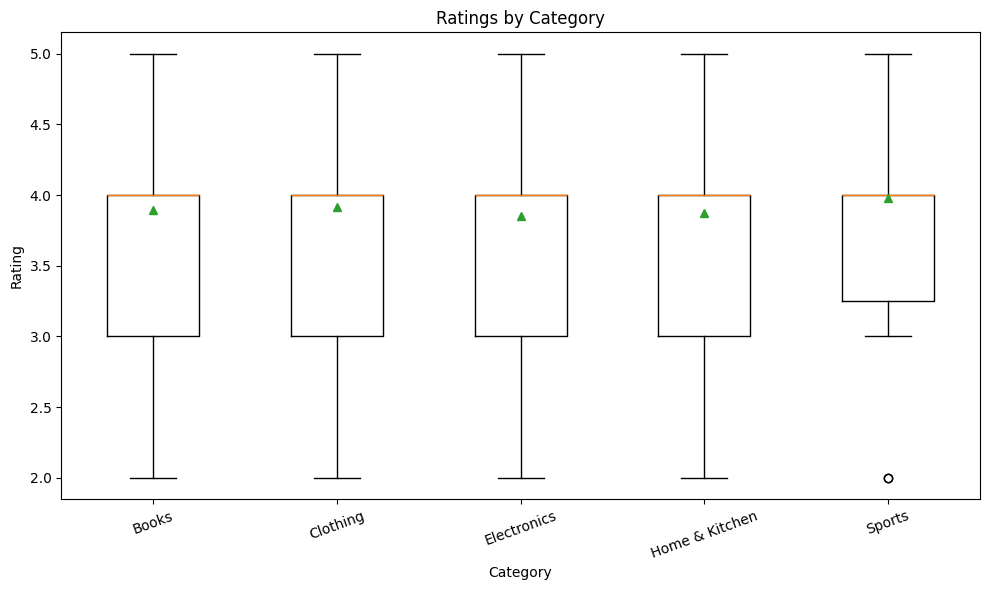

In [10]:
categories = sorted(df["category"].unique())

rating_data = [
    df.loc[df["category"] == category, "rating"]
    for category in categories
]

plt.figure(figsize=(10, 6))
plt.boxplot(
    rating_data,
    labels=categories,
    showmeans=True
)

plt.xlabel("Category")
plt.ylabel("Rating")
plt.title("Ratings by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q10. Subplots: 2 × 2 Grid


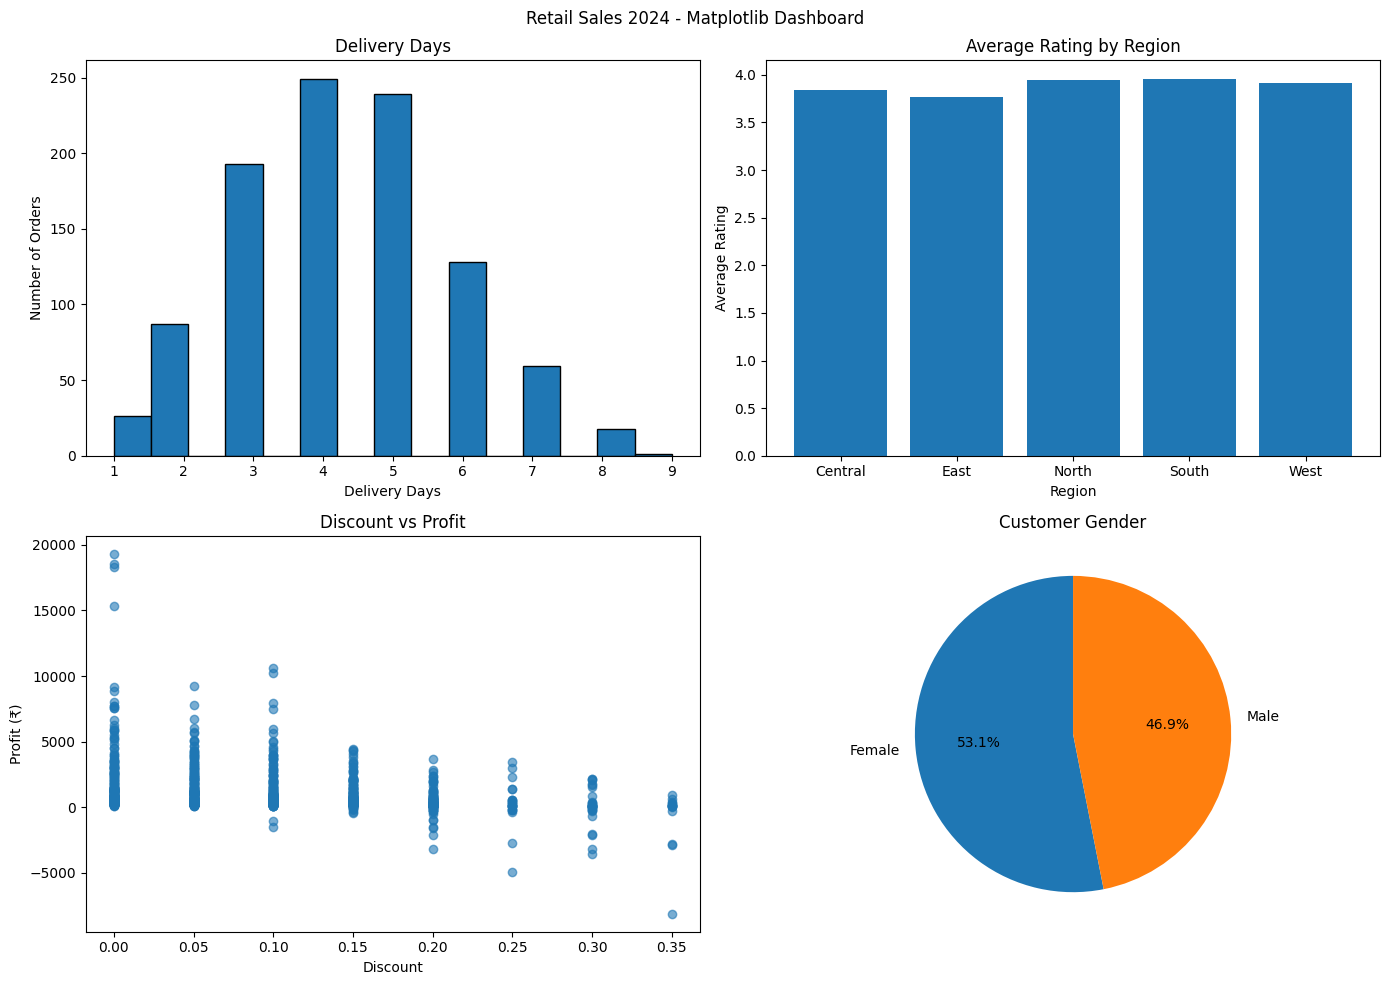

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Histogram of delivery_days
axes[0, 0].hist(df["delivery_days"], bins=15, edgecolor="black")
axes[0, 0].set_title("Delivery Days")
axes[0, 0].set_xlabel("Delivery Days")
axes[0, 0].set_ylabel("Number of Orders")

# (b) Average rating by region
avg_rating_region = df.groupby("region")["rating"].mean()

axes[0, 1].bar(avg_rating_region.index, avg_rating_region.values)
axes[0, 1].set_title("Average Rating by Region")
axes[0, 1].set_xlabel("Region")
axes[0, 1].set_ylabel("Average Rating")

# (c) Discount vs profit
axes[1, 0].scatter(df["discount"], df["profit"], alpha=0.6)
axes[1, 0].set_title("Discount vs Profit")
axes[1, 0].set_xlabel("Discount")
axes[1, 0].set_ylabel("Profit (₹)")

# (d) Customer gender
gender_counts = df["customer_gender"].value_counts()

axes[1, 1].pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 1].set_title("Customer Gender")

fig.suptitle("Retail Sales 2024 - Matplotlib Dashboard")
plt.tight_layout()
plt.savefig("matplotlib_grid.png", dpi=300, bbox_inches="tight")
plt.show()


## Part B: Seaborn – Categorical Plots (Q11 – Q18)


In [12]:
sns.set_theme(style="whitegrid", palette="Set2")


### Q11. Count Plot: Orders per Category


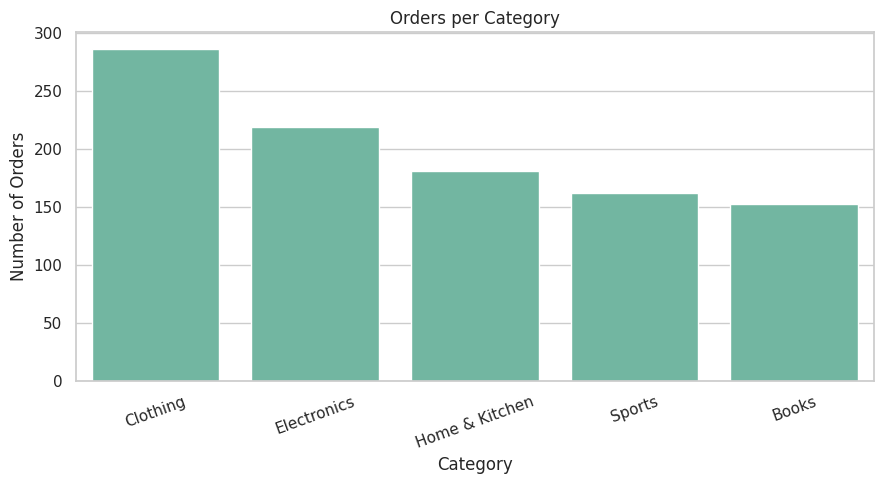

In [13]:
category_order = df["category"].value_counts().index

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="category",
    order=category_order
)

plt.xlabel("Category")
plt.ylabel("Number of Orders")
plt.title("Orders per Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q12. Count Plot with Hue


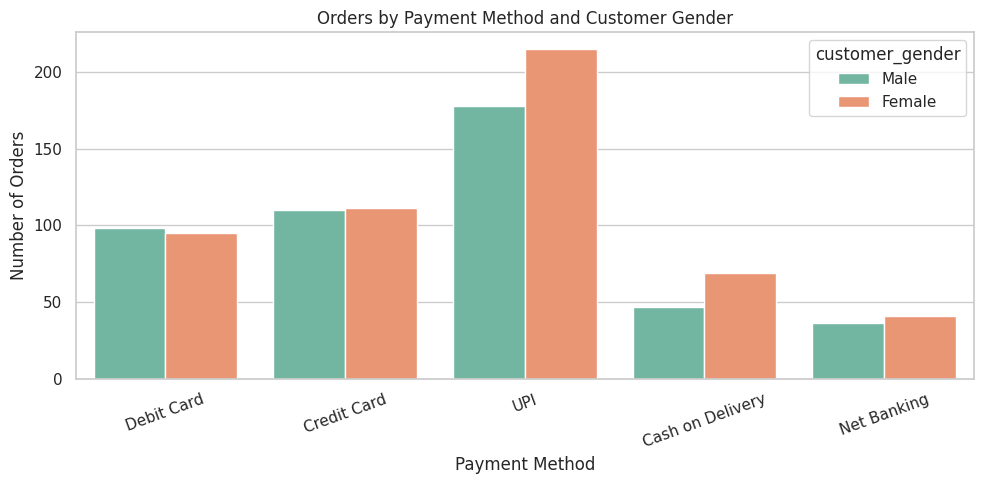

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="payment_method",
    hue="customer_gender"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.title("Orders by Payment Method and Customer Gender")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q13. Bar Plot: Average Revenue by Category


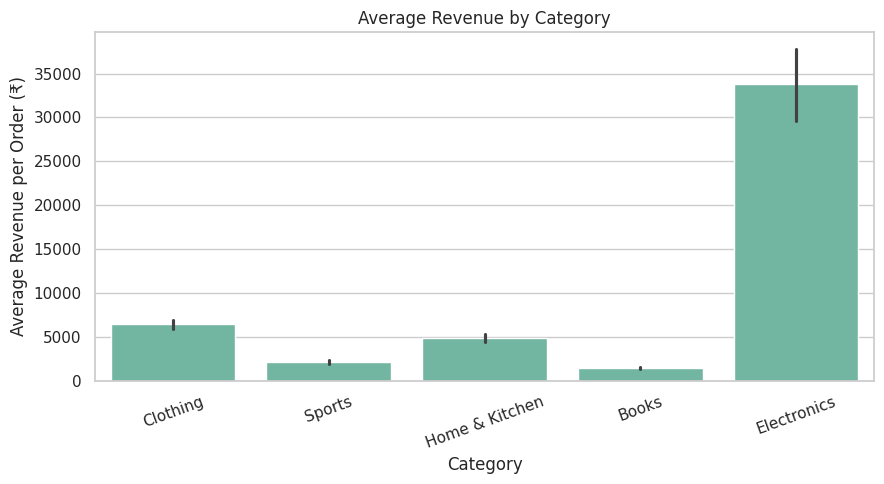

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="category",
    y="revenue"
)

# The black error bars represent the confidence interval around the estimated mean.
plt.xlabel("Category")
plt.ylabel("Average Revenue per Order (₹)")
plt.title("Average Revenue by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q14. Horizontal Bar Plot: Profit by Region


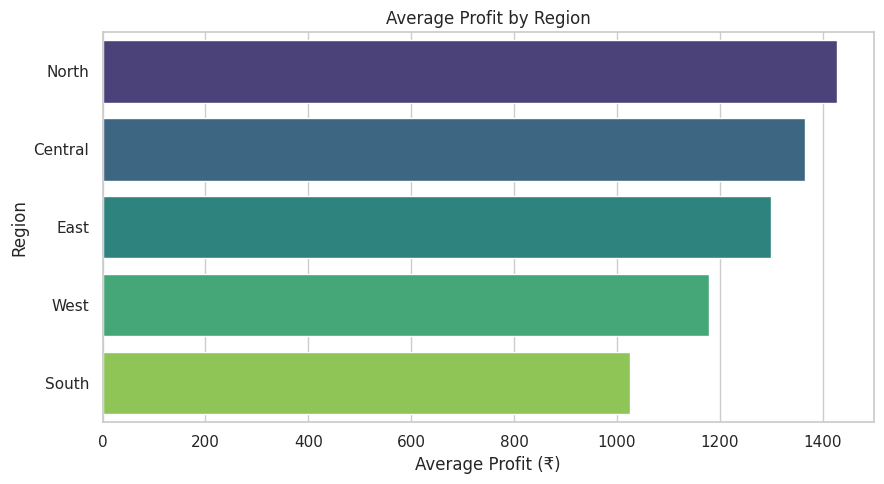

In [16]:
region_profit = (
    df.groupby("region")["profit"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_profit.values,
    y=region_profit.index,
    palette="viridis",
    hue=region_profit.index,
    legend=False
)

plt.xlabel("Average Profit (₹)")
plt.ylabel("Region")
plt.title("Average Profit by Region")
plt.tight_layout()
plt.show()


### Q15. Box Plot: Ratings by Category


Category with highest median rating: Books


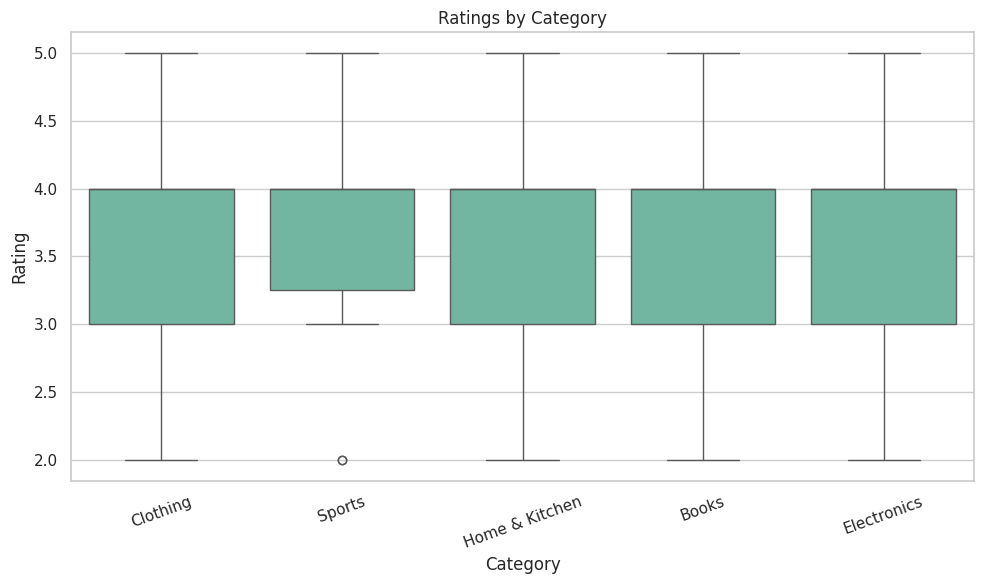

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="category",
    y="rating"
)

median_ratings = df.groupby("category")["rating"].median()
highest_median_category = median_ratings.idxmax()

# Category with the highest median rating:
print("Category with highest median rating:", highest_median_category)

plt.xlabel("Category")
plt.ylabel("Rating")
plt.title("Ratings by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q16. Violin Plot: Delivery Time by Region


Region with the slowest deliveries: East


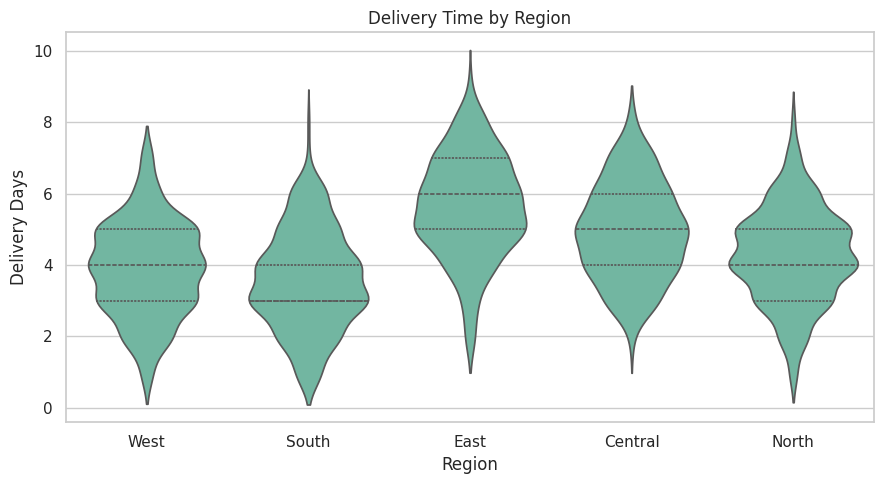

In [18]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="region",
    y="delivery_days",
    inner="quartile"
)

slowest_region = df.groupby("region")["delivery_days"].mean().idxmax()
print("Region with the slowest deliveries:", slowest_region)

plt.xlabel("Region")
plt.ylabel("Delivery Days")
plt.title("Delivery Time by Region")
plt.tight_layout()
plt.show()


### Q17. Box Plot + Strip Plot


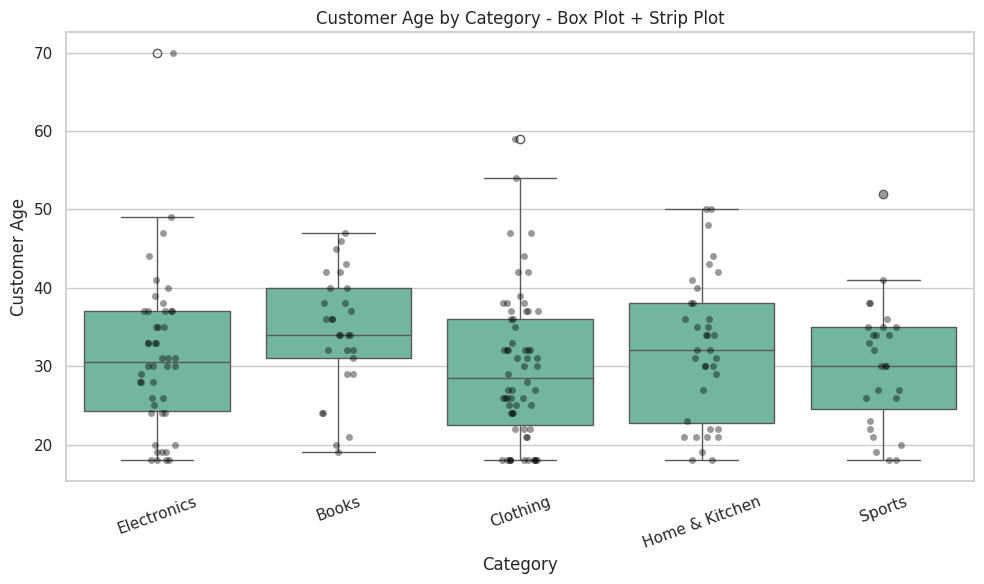

In [19]:
sample_df = df.sample(200, random_state=1)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=sample_df,
    x="category",
    y="customer_age"
)

sns.stripplot(
    data=sample_df,
    x="category",
    y="customer_age",
    color="black",
    alpha=0.4,
    jitter=True
)

plt.xlabel("Category")
plt.ylabel("Customer Age")
plt.title("Customer Age by Category - Box Plot + Strip Plot")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Q18. Point Plot: Average Rating


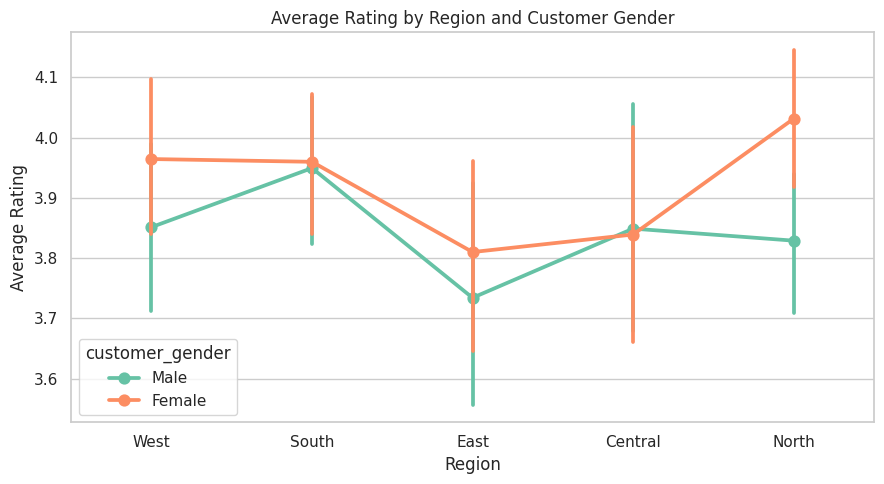

In [20]:
plt.figure(figsize=(9, 5))

sns.pointplot(
    data=df,
    x="region",
    y="rating",
    hue="customer_gender"
)

plt.xlabel("Region")
plt.ylabel("Average Rating")
plt.title("Average Rating by Region and Customer Gender")
plt.tight_layout()
plt.show()


## Part C: Seaborn – Distribution Plots (Q19 – Q21)


### Q19. Histogram with KDE


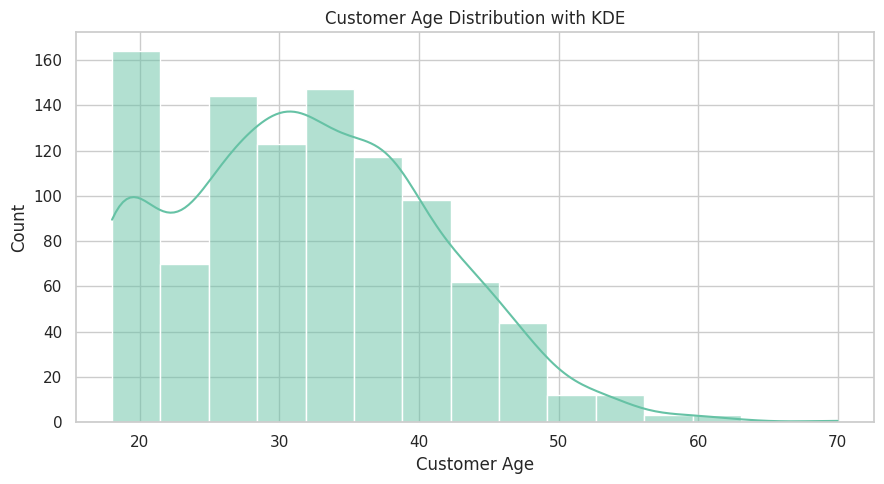

In [21]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="customer_age",
    bins=15,
    kde=True
)

plt.xlabel("Customer Age")
plt.ylabel("Count")
plt.title("Customer Age Distribution with KDE")
plt.tight_layout()
plt.show()


### Q20. Histogram by Group


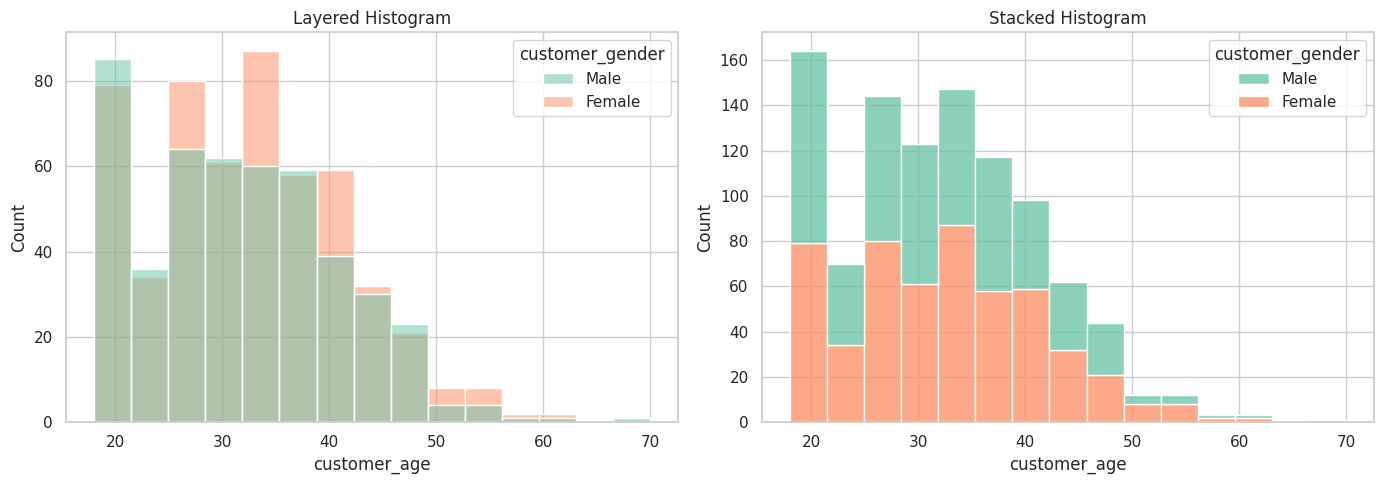

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="customer_age",
    hue="customer_gender",
    bins=15,
    multiple="layer",
    alpha=0.5,
    ax=axes[0]
)
axes[0].set_title("Layered Histogram")

sns.histplot(
    data=df,
    x="customer_age",
    hue="customer_gender",
    bins=15,
    multiple="stack",
    ax=axes[1]
)
axes[1].set_title("Stacked Histogram")

# Layer mode overlays the gender distributions, making their shapes easier to compare.
# Stack mode places the groups on top of each other, showing the combined count in each bin.
plt.tight_layout()
plt.show()


### Q21. KDE Plot


Two most similar delivery-time distributions (based on mean and standard deviation): ('South', 'West')


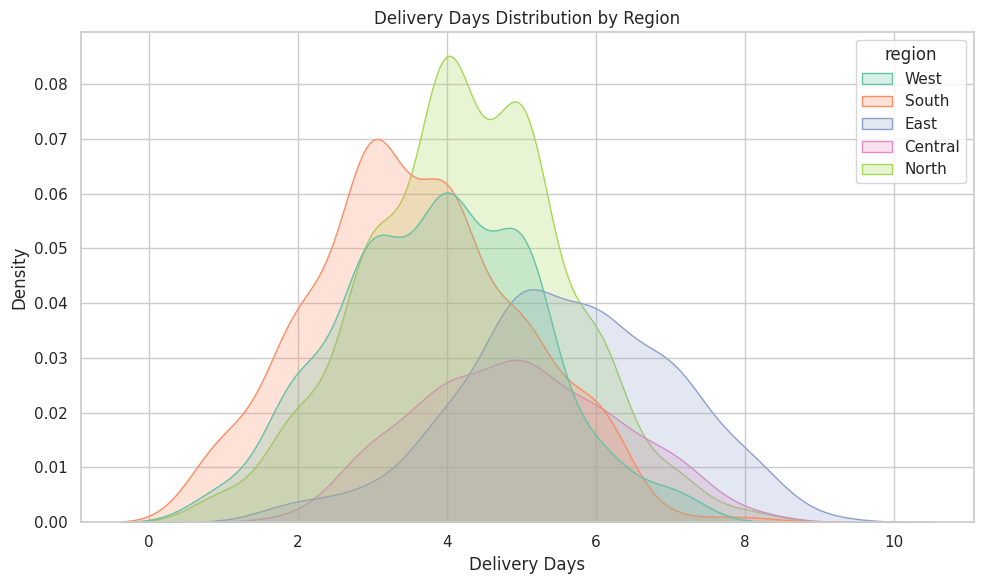

In [23]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df,
    x="delivery_days",
    hue="region",
    fill=True
)

region_stats = df.groupby("region")["delivery_days"].agg(["mean", "std"])
region_names = list(region_stats.index)

best_pair = None
best_distance = float("inf")

for i in range(len(region_names)):
    for j in range(i + 1, len(region_names)):
        a = region_stats.loc[region_names[i]]
        b = region_stats.loc[region_names[j]]
        distance = abs(a["mean"] - b["mean"]) + abs(a["std"] - b["std"])
        if distance < best_distance:
            best_distance = distance
            best_pair = (region_names[i], region_names[j])

print("Two most similar delivery-time distributions (based on mean and standard deviation):", best_pair)

plt.xlabel("Delivery Days")
plt.ylabel("Density")
plt.title("Delivery Days Distribution by Region")
plt.tight_layout()
plt.show()


## Part D: Seaborn – Relationship Plots (Q22 – Q27)


### Q22. Scatter Plot


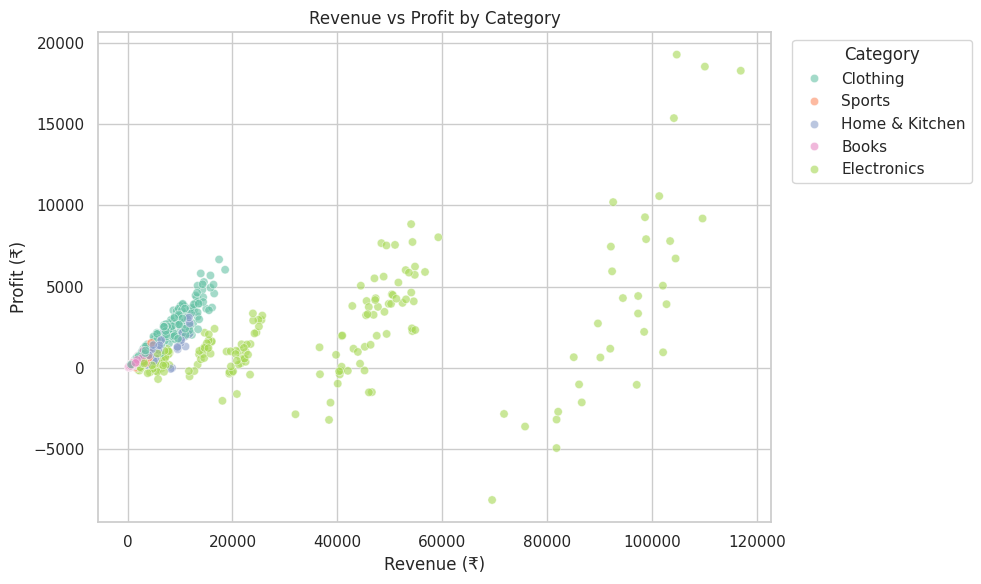

In [24]:
plt.figure(figsize=(10, 6))

ax = sns.scatterplot(
    data=df,
    x="revenue",
    y="profit",
    hue="category",
    alpha=0.6
)

ax.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xlabel("Revenue (₹)")
plt.ylabel("Profit (₹)")
plt.title("Revenue vs Profit by Category")
plt.tight_layout()
plt.show()


### Q23. Regression Plot


Correlation = -0.548; relationship: negative


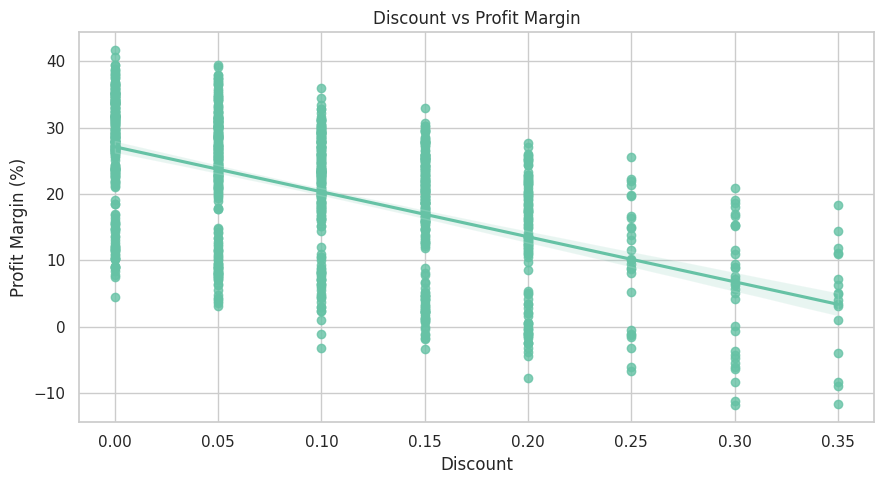

In [25]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="discount",
    y="profit_margin"
)

correlation = df["discount"].corr(df["profit_margin"])

if correlation > 0.05:
    relationship = "positive"
elif correlation < -0.05:
    relationship = "negative"
else:
    relationship = "none / very weak"

# The relationship is described using the sign of the correlation coefficient.
print(f"Correlation = {correlation:.3f}; relationship: {relationship}")

plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")
plt.title("Discount vs Profit Margin")
plt.tight_layout()
plt.show()


### Q24. Line Plot with Hue


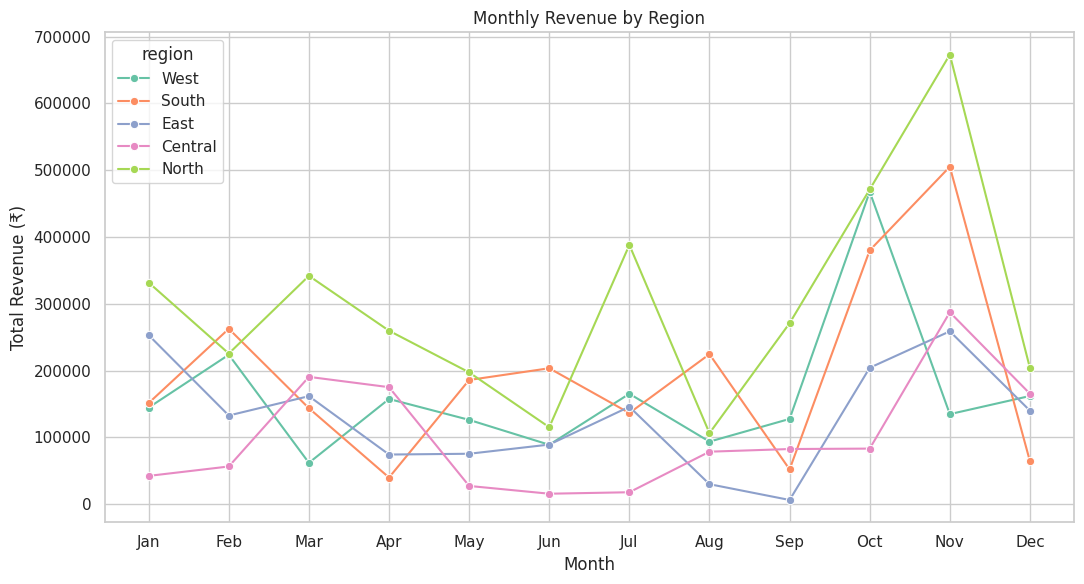

In [26]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=df,
    x="month",
    y="revenue",
    hue="region",
    estimator="sum",
    errorbar=None,
    marker="o"
)

plt.xticks(range(1, 13), month_names)
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.title("Monthly Revenue by Region")
plt.tight_layout()
plt.show()


### Q25. Heatmap: Correlation Matrix


Two most strongly correlated pairs:
('month', 'quarter') = 0.9752389591406673
('unit_price', 'revenue') = 0.924084684779644


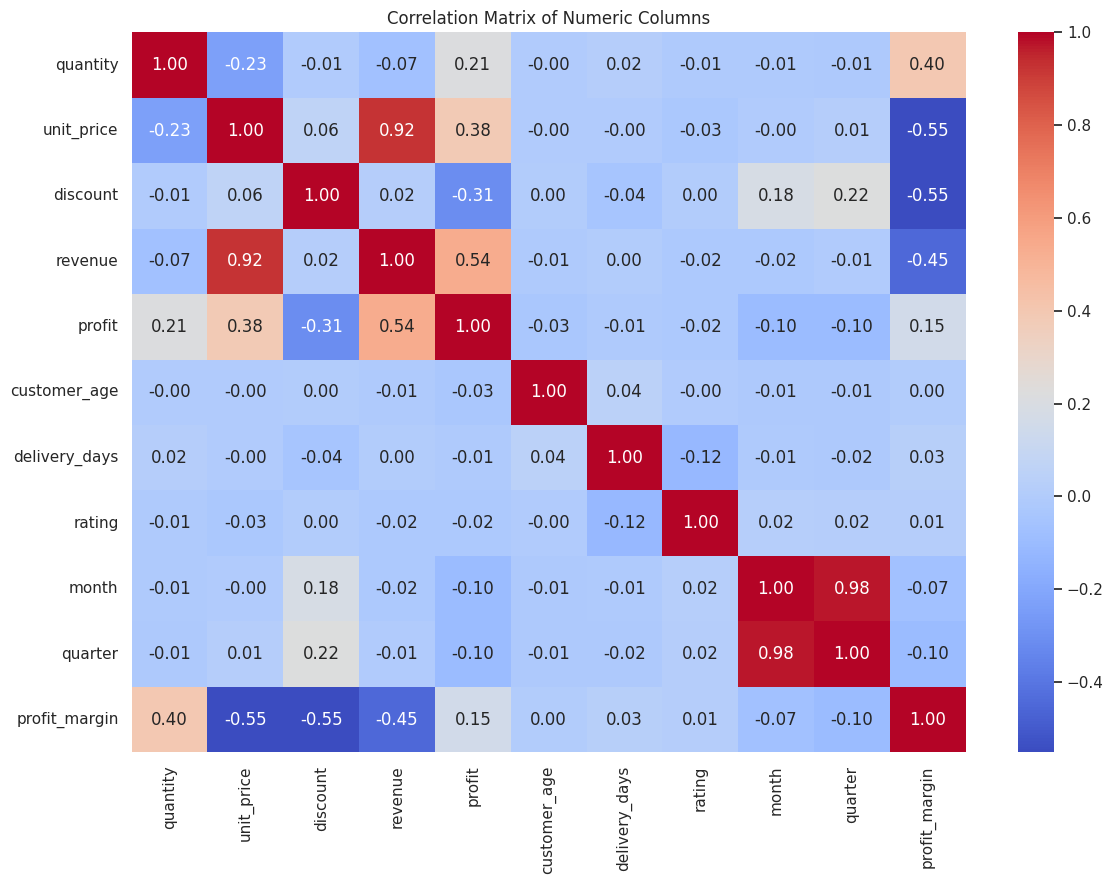

In [27]:
numeric_df = df.select_dtypes("number")
corr = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# Find the two strongest absolute correlations excluding self-correlation.
corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

strongest_pairs = corr_pairs.abs().sort_values(ascending=False).head(2)

print("Two most strongly correlated pairs:")
for pair, value in strongest_pairs.items():
    print(pair, "=", corr_pairs[pair])

plt.title("Correlation Matrix of Numeric Columns")
plt.tight_layout()
plt.show()


### Q26. Heatmap: Pivot Table


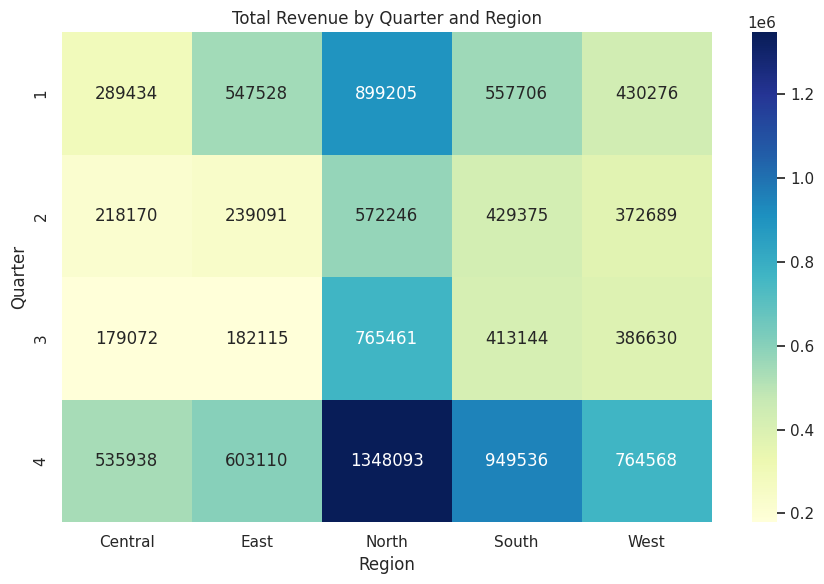

In [28]:
pivot_revenue = pd.pivot_table(
    df,
    values="revenue",
    index="quarter",
    columns="region",
    aggfunc="sum"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    pivot_revenue,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.xlabel("Region")
plt.ylabel("Quarter")
plt.title("Total Revenue by Quarter and Region")
plt.tight_layout()
plt.show()


### Q27. Joint Plot


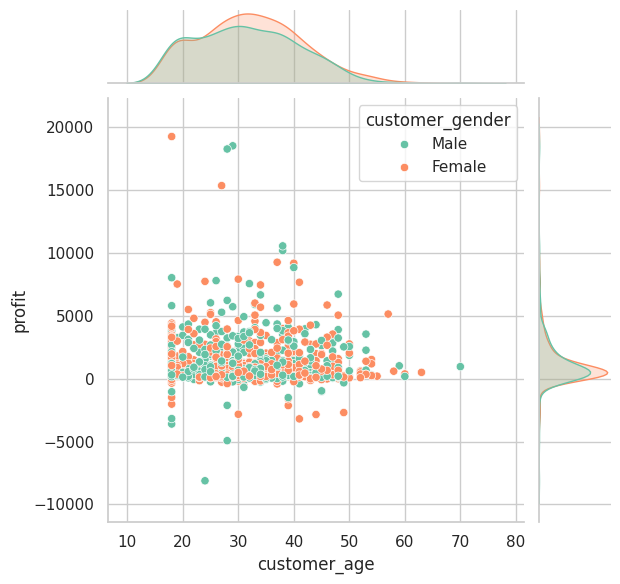

In [29]:
g = sns.jointplot(
    data=df,
    x="customer_age",
    y="profit",
    hue="customer_gender"
)

# The top marginal plot shows the distribution of customer_age.
# The right marginal plot shows the distribution of profit.
plt.show()


## Part E: Seaborn – Grids and Dashboard (Q28 – Q30)


### Q28. Pair Plot


Pair showing the clearest numerical pattern: ('revenue', 'profit')
Correlation: 0.5353617490371991


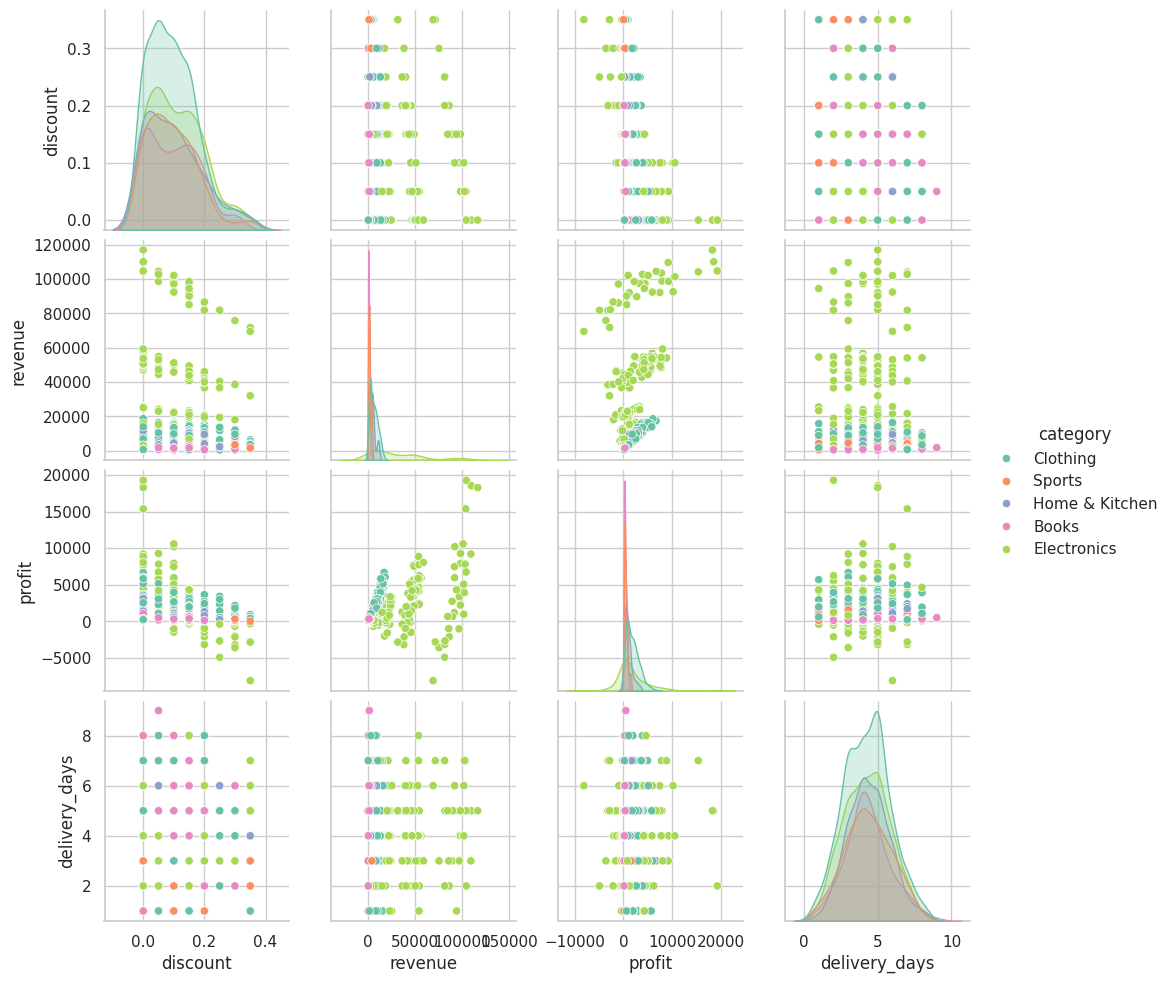

In [30]:
pair_data = df[
    ["discount", "revenue", "profit", "delivery_days", "category"]
]

g = sns.pairplot(
    pair_data,
    hue="category",
    diag_kind="kde"
)

# Identify the strongest pairwise relationship numerically.
pair_corr = df[
    ["discount", "revenue", "profit", "delivery_days"]
].corr()

upper = pair_corr.where(
    np.triu(np.ones(pair_corr.shape), k=1).astype(bool)
).stack()

strongest_pair = upper.abs().idxmax()
print("Pair showing the clearest numerical pattern:", strongest_pair)
print("Correlation:", upper[strongest_pair])

plt.show()


### Q29. Faceted Bar Plots


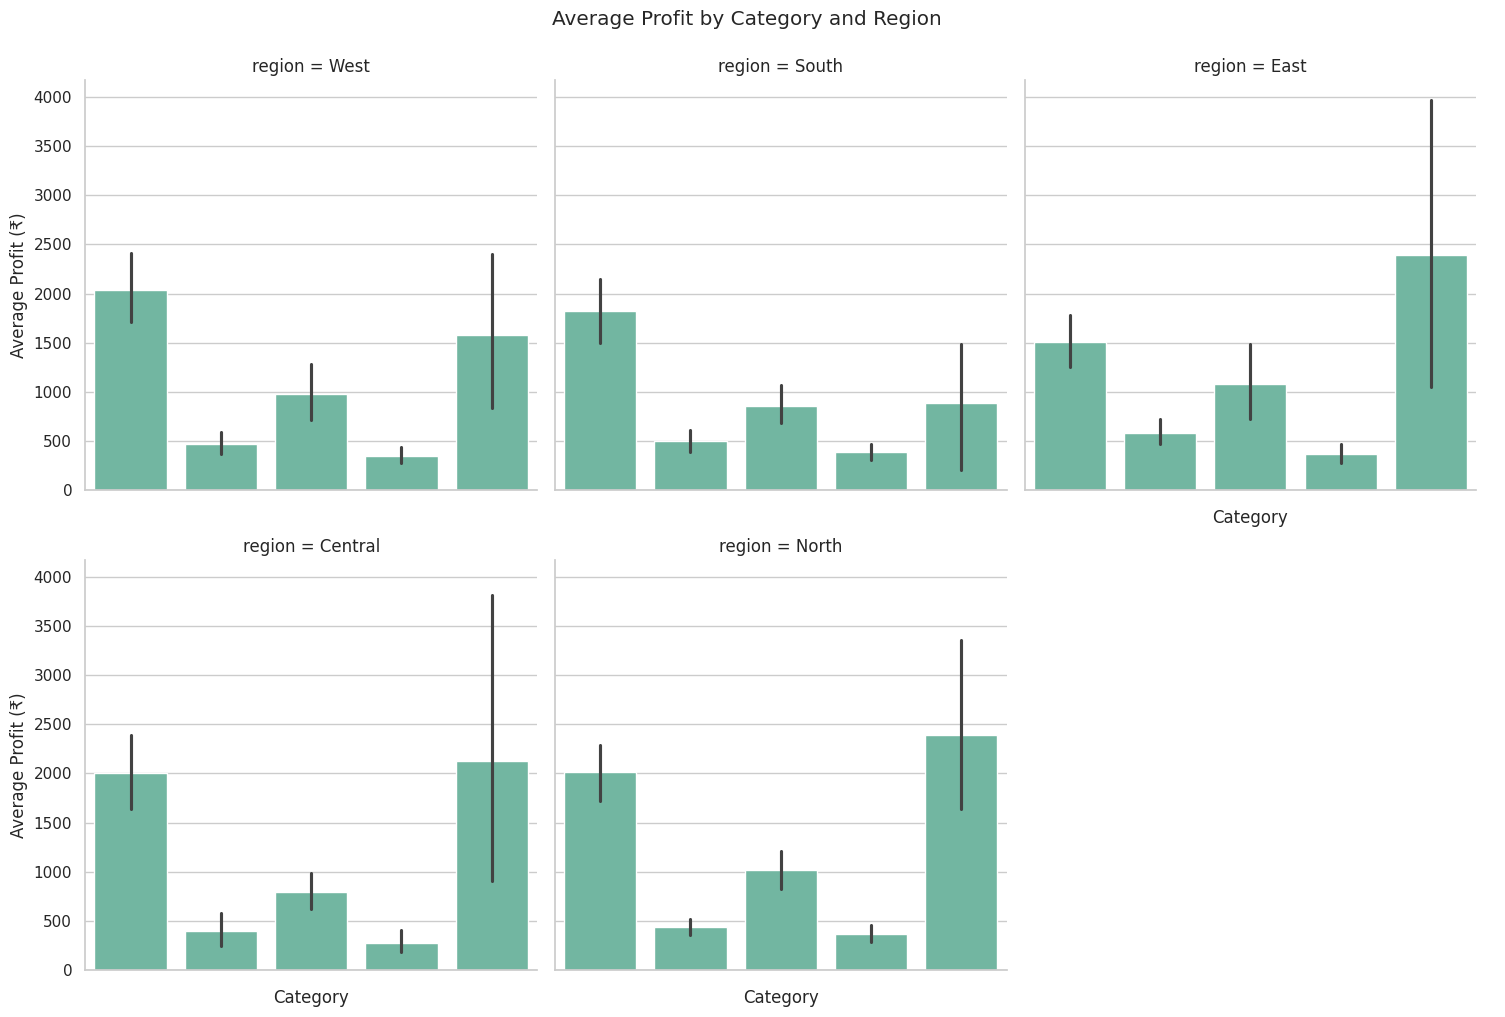

In [31]:
g = sns.catplot(
    data=df,
    kind="bar",
    x="category",
    y="profit",
    col="region",
    col_wrap=3
)

g.set_xticklabels(rotation=45)
g.set_axis_labels("Category", "Average Profit (₹)")
g.fig.suptitle("Average Profit by Category and Region", y=1.03)

plt.show()


### Q30. Mini Dashboard


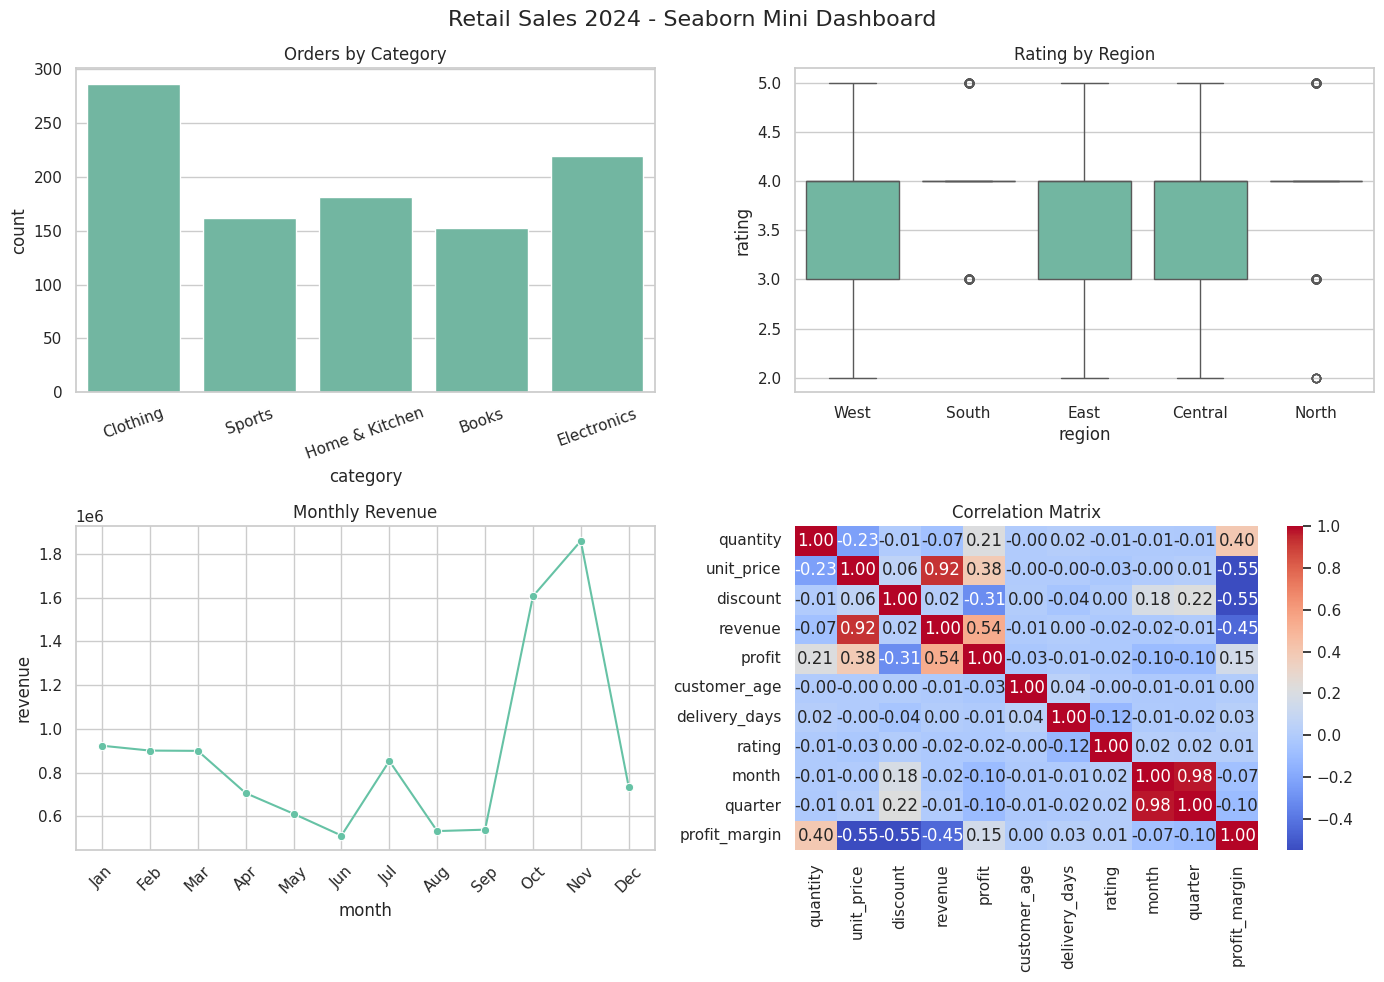

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: countplot of category
sns.countplot(
    data=df,
    x="category",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Orders by Category")
axes[0, 0].tick_params(axis="x", rotation=20)

# Top-right: boxplot of rating by region
sns.boxplot(
    data=df,
    x="region",
    y="rating",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Rating by Region")

# Bottom-left: lineplot of monthly revenue
monthly_revenue = df.groupby("month", as_index=False)["revenue"].sum()

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    marker="o",
    errorbar=None,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly Revenue")
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].set_xticklabels(month_names)
axes[1, 0].tick_params(axis="x", rotation=45)

# Bottom-right: correlation heatmap
corr = df.select_dtypes("number").corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Matrix")

fig.suptitle(
    "Retail Sales 2024 - Seaborn Mini Dashboard",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
